# 02 - Baseline models

All numbers are read from `reports/metrics/` produced by `scripts/train.py` (3x repeated stratified 5-fold CV on the 614-patient training set) and `scripts/evaluate.py` (test set).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from src.config import load_config
cfg = load_config()
M = cfg.path("paths", "metrics_dir"); F = cfg.path("paths", "figures_dir")
pd.set_option("display.precision", 4); pd.set_option("display.width", 200)
def show(name): display(Image(filename=str(F / name)))

In [2]:
cv = pd.read_csv(M / 'cv_summary.csv')
base = cv[~cv.tuned & ~cv.smote]
base[['candidate','accuracy_mean','precision_mean','recall_mean','f1_mean','roc_auc_mean','pr_auc_mean','specificity_mean','brier_mean']].sort_values('pr_auc_mean', ascending=False)

,candidate,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,pr_auc_mean,specificity_mean,brier_mean
8,logistic_regression_nosmote_default,0.7829,0.7523,0.5735,0.6461,0.8425,0.7406,0.8950,0.1520
4,extratrees_nosmote_default,0.7672,0.7433,0.5207,0.6072,0.8415,0.7397,0.8992,0.1573
13,stacking_nosmote_default,0.7601,0.7019,0.5626,0.6198,0.8324,0.7298,0.8658,0.1601
10,random_forest_nosmote_default,0.7601,0.6922,0.5798,0.6263,0.8250,0.7182,0.8567,0.1608
0,catboost_nosmote_default,0.7465,0.6558,0.6031,0.6242,0.8135,0.7157,0.8233,0.1769
17,xgboost_nosmote_default,0.7465,0.6585,0.5999,0.6228,0.8030,0.6927,0.8250,0.1823


## Reproduce one baseline live
The CV engine refits the full pipeline (impute -> model) inside each fold.

In [3]:
from src.data.loader import load_split
from src.models.registry import CandidateSpec
from src.training.cross_validation import cross_validate_model
X_tr, X_te, y_tr, y_te = load_split(cfg)
res = cross_validate_model(CandidateSpec('logistic_regression', smote=False, tuned=False).build(cfg), X_tr, y_tr, 5, 3, cfg.seed)
res.fold_metrics[['f1','recall','precision','roc_auc','pr_auc','brier']].agg(['mean','std'])

,f1,recall,precision,roc_auc,pr_auc,brier
mean,0.6461,0.5735,0.7523,0.8425,0.7406,0.1520
std,0.0661,0.0811,0.0766,0.0269,0.0599,0.0146


Accuracy alone is misleading here: a model predicting 'non-diabetic' for everyone scores ~65% accuracy with zero recall.

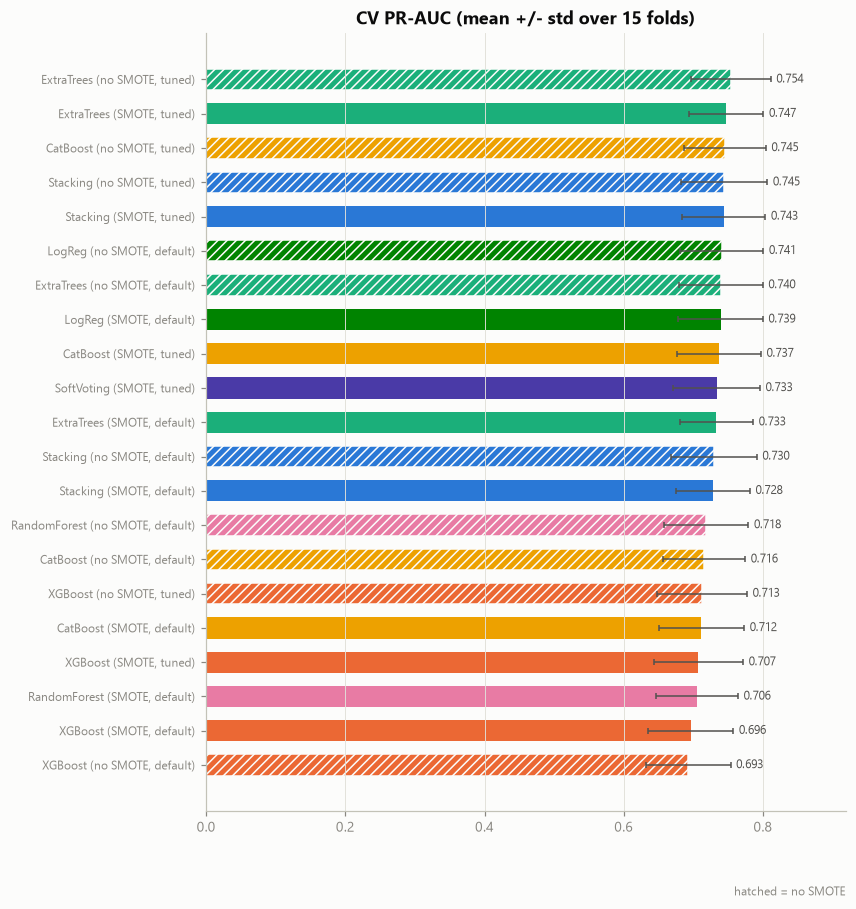

In [4]:
show('cv_pr_auc_comparison.png')

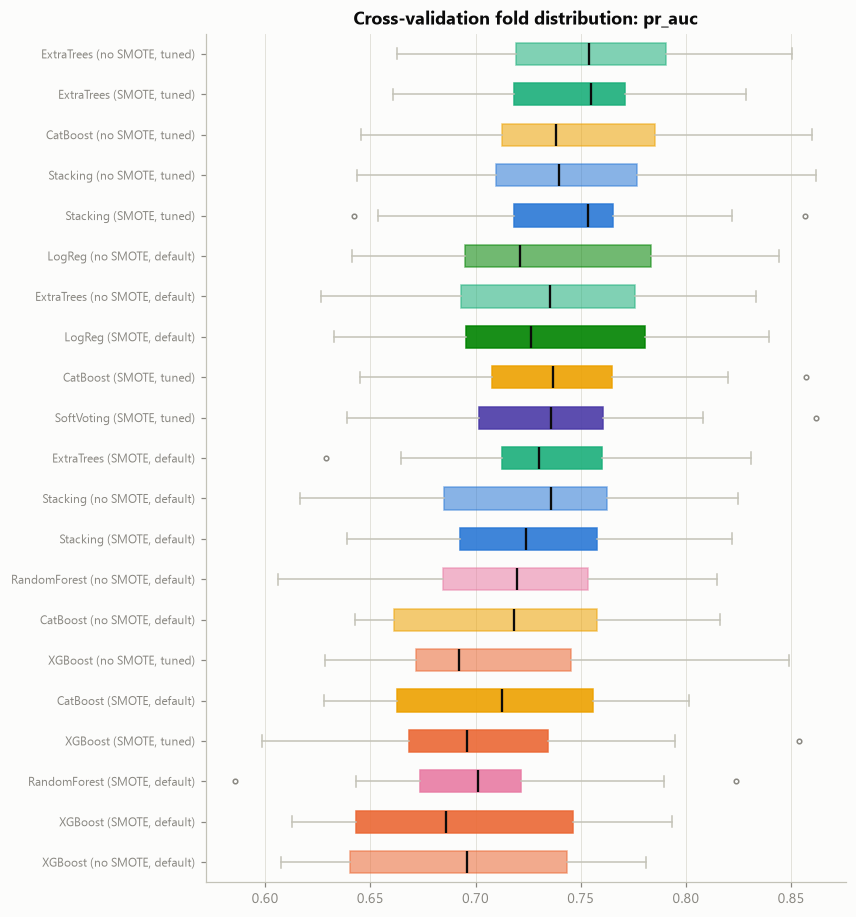

In [5]:
show('cv_boxplot_pr_auc.png')